# Optical gas density: reconstructing a field and tracing its uncertainty

This active review reconstructs every32×32 author-existing simulated displacement sample using local explicit mathematics. The target is depth-averaged density and conditional standard uncertainty. There is no independent true density array. The qualified original run, the original unit-defective result, and fresh local reconstructions remain separately labeled.

## 1. Problem

### Data: complete native observations

Background-oriented schlieren observes the displacement of a dot pattern through refractive-index gradients. For a known gas composition, Gladstone–Dale converts refractive index to density. The grid contains all1024 native nodes; the complete perimeter is independently prescribed ambient density. The existing sample optical layout is used as published in the author program, not claimed identical to every paper experiment.

{
  "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "Agg",
  "raw_sha256": "a49b86be1b9adfa2da85f0047ae9260bbaf97a11a7cbbb203a1c5404254a6e0c"
}


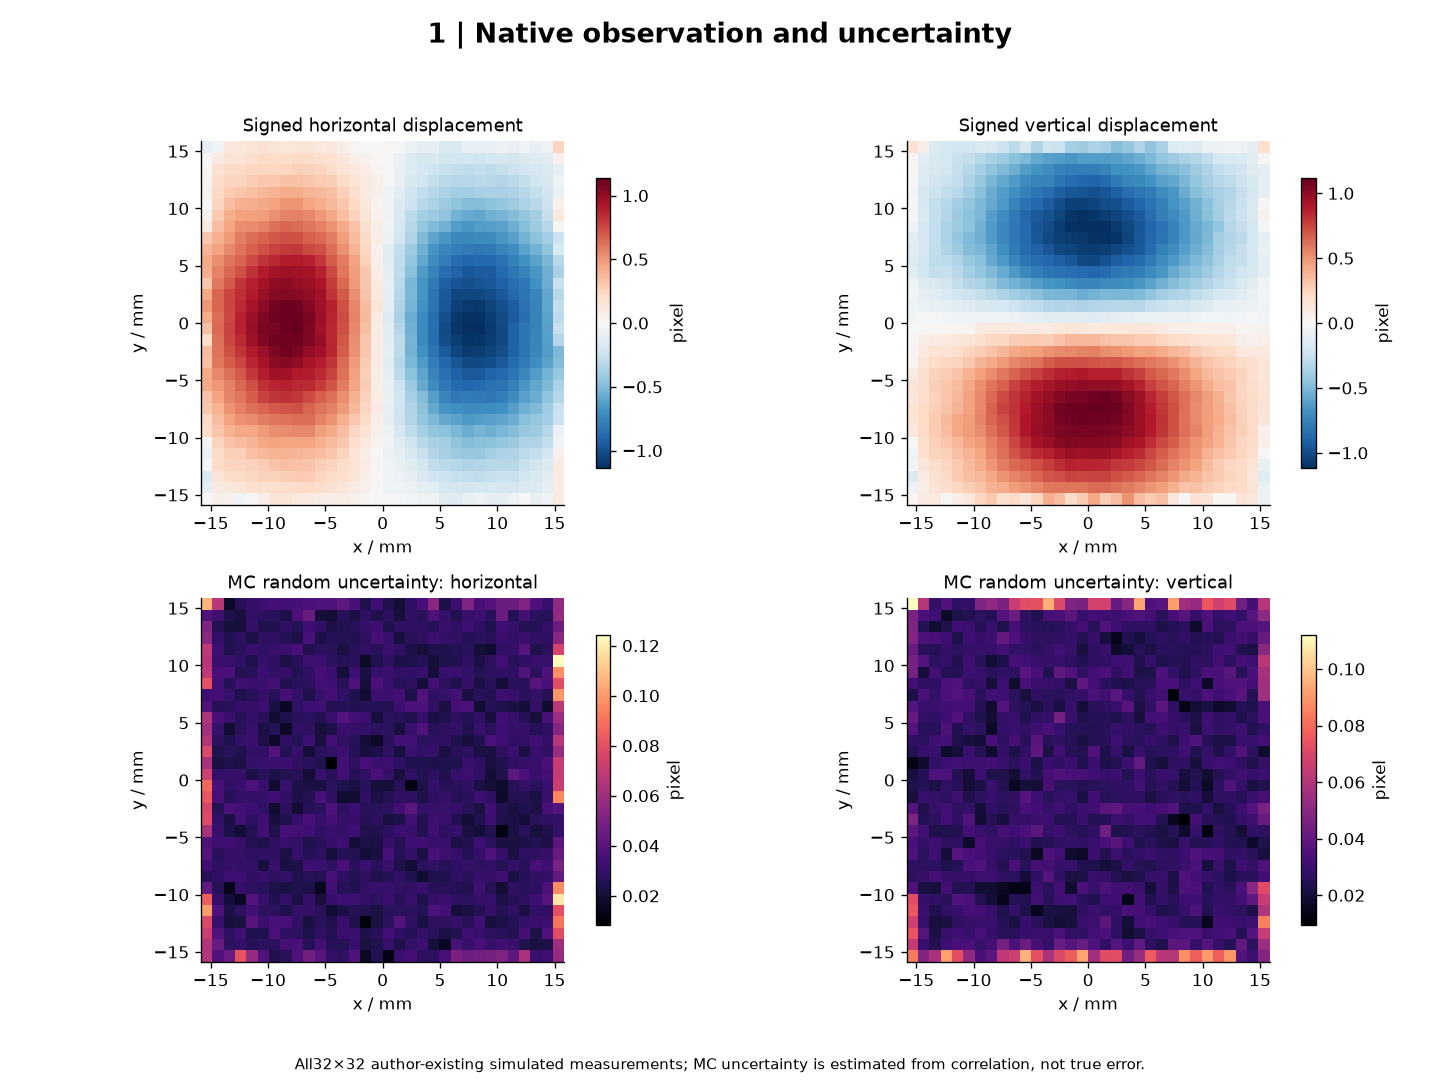

In [1]:
from pathlib import Path
import os,sys,time,json,tempfile,hashlib
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').is_file()
sys.path.insert(0,str(ROOT))
import numpy as np, scipy, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
def show_inline(fig):
    buffer=BytesIO();fig.savefig(buffer,format="png",dpi=120);display(Image(data=buffer.getvalue()))
from src.preprocessing import load_observations
from src.physics_model import calibrate, MAGNIFICATION, MAGNIFICATION_SIGMA, DISTANCE, DISTANCE_SIGMA, REFRACTIVE_AMBIENT, PIXEL_PITCH, GLADSTONE_DALE, DEPTH
from src.solvers import reconstruct,integrate_wls
from src.generate_data import add_displacement_noise,conditional_density_samples
from src import visualization as viz
START=time.perf_counter()
FIGDIR=Path(os.environ.get('IMAGING_PRIVATE_FIGURE_DIR',tempfile.mkdtemp(prefix='bos_science_')))
FIGDIR.mkdir(parents=True,exist_ok=True)
environment=dict(sys_executable=sys.executable,python=sys.version,numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,backend=matplotlib.get_backend(),raw_sha256=hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print(json.dumps(environment,indent=2))
obs=load_observations(ROOT/'data/raw_data.npz')
pos=obs['positions'][0];disp=obs['displacement'][0];sigma=obs['displacement_sigma'][0]
cal=calibrate(pos[...,0],pos[...,1],disp[...,0],disp[...,1],sigma[...,0],sigma[...,1])
x,y,gx,gy,sgx,sgy=cal
extent=[x.min()*1000,x.max()*1000,y.min()*1000,y.max()*1000]
fig=viz.observations(pos,disp,sigma,extent);viz.save_group(fig,FIGDIR,'figure01_observations');show_inline(fig);plt.close(fig)

## 2. Physics, units and source qualification

Let U,V be signed sensor displacements in pixels; p is pixel pitch, M magnification, Z pattern-to-flow distance, L slab thickness, K the Gladstone–Dale coefficient and n0 ambient refractive index. With c=n0p/(MZKL), density gradients are gx=cU and gy=cV in kg/m⁴. Coordinates x,y are in meters. The first-order conditional gradient variance is

$$s_{g_x}^2=(c s_U)^2+(cU s_M/M)^2+(cU s_Z/Z)^2.$$

The supplied sU,sV are observation-derived MC random uncertainties after correlation-peak bias variance removal. The calibration standard uncertainties are sM and sZ. Their contributions are treated independently between nodes in the selected source covariance model. That approximation does not capture a genuinely common calibration error, and the large sM makes linear propagation only a conditional approximation.

The unchanged source mean law contains n0/L, while its three uncertainty factors omit L and divide by n0. Independent units and finite differences prove the discrepancy. The minimum qualified source correction replaces those factors with derivatives of the same mean law; the corrected/source sigma ratio is n0²/L=100.0551325969 when L is expressed in meters. All observations, integration operators and boundary values remain unchanged. This notebook does not call the upstream library.

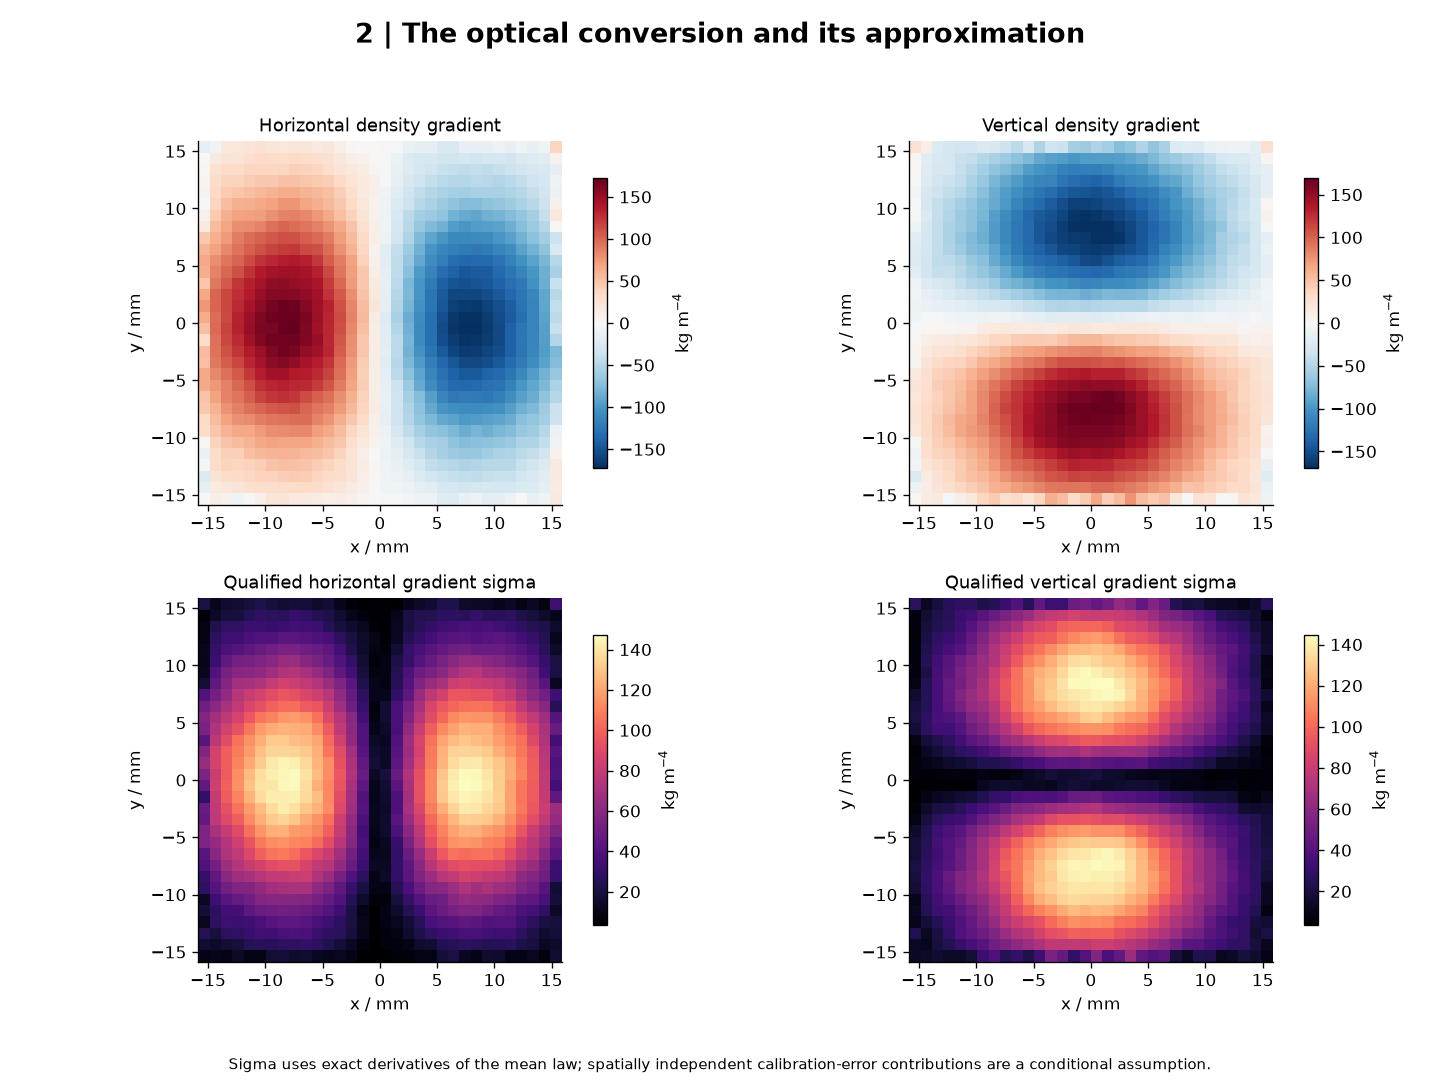

Calibrated gradient range: -172.760561408762 171.97881601961473 kg/m4


In [2]:
fig=viz.calibration(cal,extent);viz.save_group(fig,FIGDIR,'figure02_physics');show_inline(fig);plt.close(fig)
print('Calibrated gradient range:',float(min(gx.min(),gy.min())),float(max(gx.max(),gy.max())),'kg/m4')

## 3. Method: weighted integration and full covariance propagation

The unknown vectorρ contains every native density sample. D stacks992 horizontal and992 vertical forward differences followed by124 perimeter selectors scaled by inverse horizontal spacing. B averages nodal gradients to each edge; C inserts scaled boundary density d. For stacked nodal gradients g, form b=Bg+Cd and covariance Q=B diag(sg²)Bᵀ+C diag(sd²)Cᵀ. The weights W=diag(1/diag(Q)) use marginal variances. The objective and propagated covariance are

$$J(\rho)=\tfrac12(D\rho-b)^{\mathsf T}W(D\rho-b),\qquad A=D^{\mathsf T}WD,$$
$$\hat\rho=A^{-1}D^{\mathsf T}Wb,\qquad \Sigma_\rho=A^{-1}D^{\mathsf T}WQWD A^{-\mathsf T}.$$

Here sd=10⁻¹⁰kg/m³ is the boundary standard uncertainty, Σρ is conditional density covariance, and reported density_sigma is the square root of its diagonal. Shared-edge covariance in Q is retained during propagation; the method is diagonal WLS rather than full GLS. A direct sparse solve evaluates the closed form; there is no artificial iteration. The Poisson comparison uses centered divergence and the five-point Laplacian with the same complete Dirichlet perimeter. Both paths below are computed now from the public observations.

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.225009875289088e-20.
  inv=linalg.inv(normal.toarray())


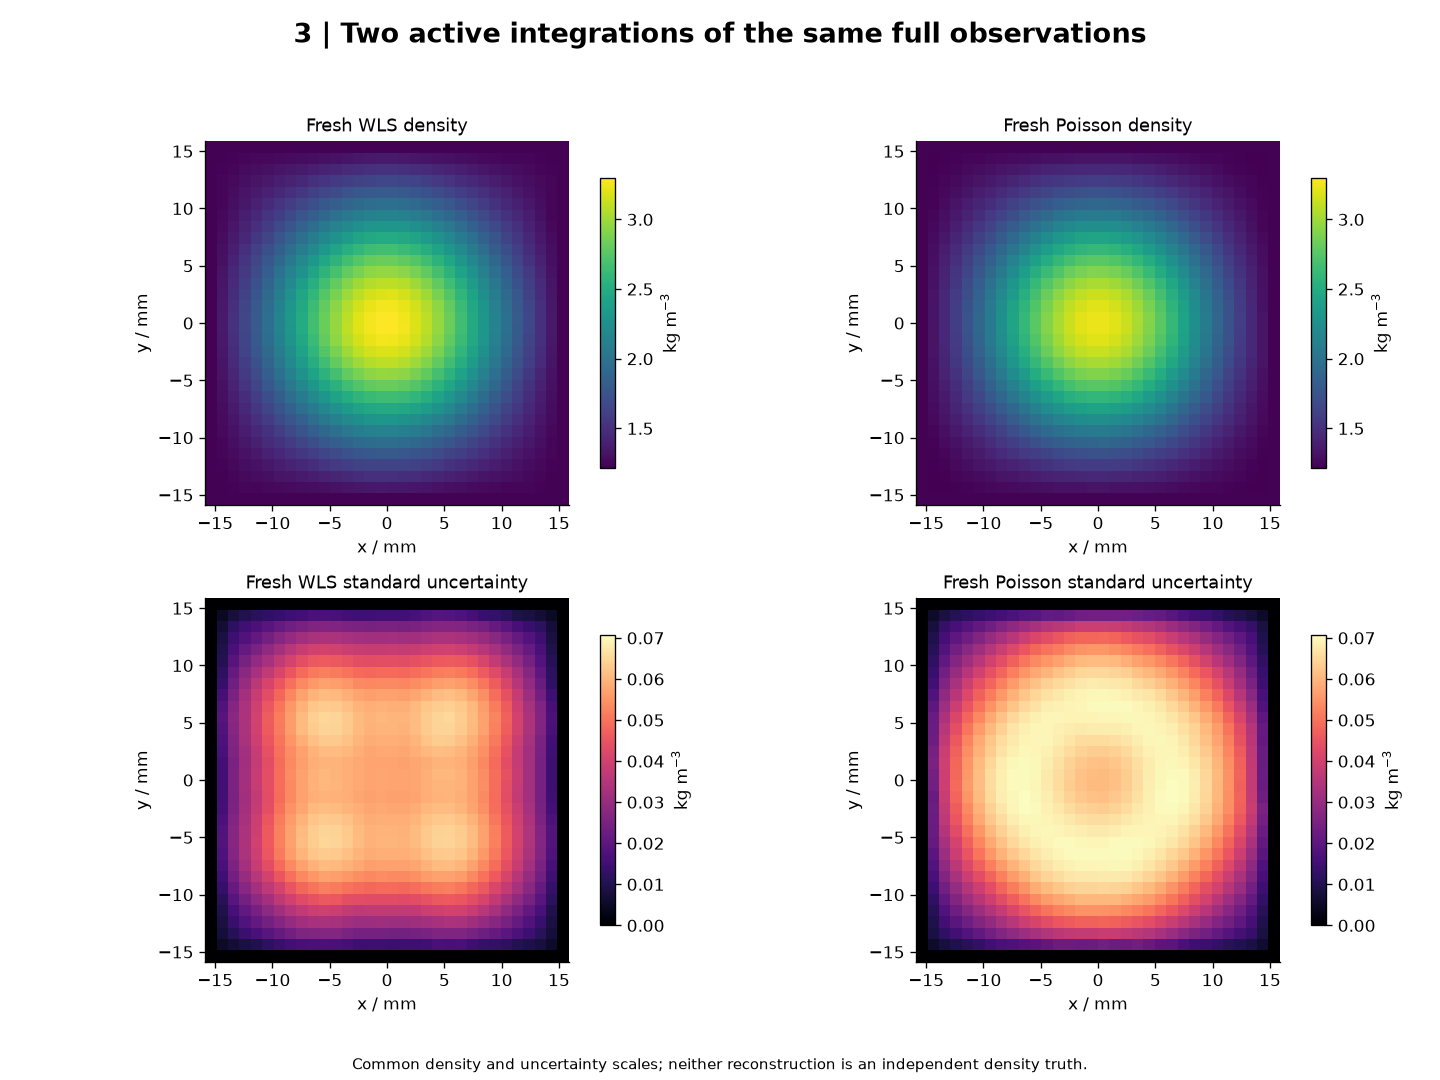

Fresh WLS/Poisson runtimes: 0.25254380000114907 0.28552040000795387


In [3]:
t=time.perf_counter();wls=reconstruct(obs);wls_seconds=time.perf_counter()-t
t=time.perf_counter();poisson=reconstruct(obs,method='poisson');poisson_seconds=time.perf_counter()-t
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/qualified_upstream.npz',allow_pickle=False))
uncorrected=dict(np.load(ROOT/'notebooks/reference_outputs/uncorrected_upstream.npz',allow_pickle=False))
fig=viz.results(wls,poisson,extent);viz.save_group(fig,FIGDIR,'figure03_reconstruction');show_inline(fig);plt.close(fig)
print('Fresh WLS/Poisson runtimes:',wls_seconds,poisson_seconds)

## 4. Results: reference agreement and physical residual

The qualified original is a method reference, not true density. Compare the fresh result against that independently captured run, and separately inspect consistency with all measured gradient edges and known boundary rows. Cosine similarity uses no mean subtraction; range-NRMSE is RMS difference divided by the reference range, separately for density and standard uncertainty. Signed maps below have symmetric limits containing every displayed value. Near-zero reproduction error has its own colorbar and must not be mistaken for the much larger Poisson–WLS difference.

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999999,
    "reconstruction_nrmse": 6.738994485430225e-15,
    "density_sigma_ncc": 1.0,
    "density_sigma_nrmse": 4.567946366705146e-15,
    "forward_rms": 0.46454223101939995
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 3.539330494974542e-08
    },
    "density_sigma_ncc": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "density_sigma_nrmse": {
      "comparison": "<=",
      "boundary": 2.2615553491073282e-08
    },
    "forward_rms": {
      "comparison": "<=",
      "boundary": 0.4877693425703862
    }
  },
  "errors": []
}


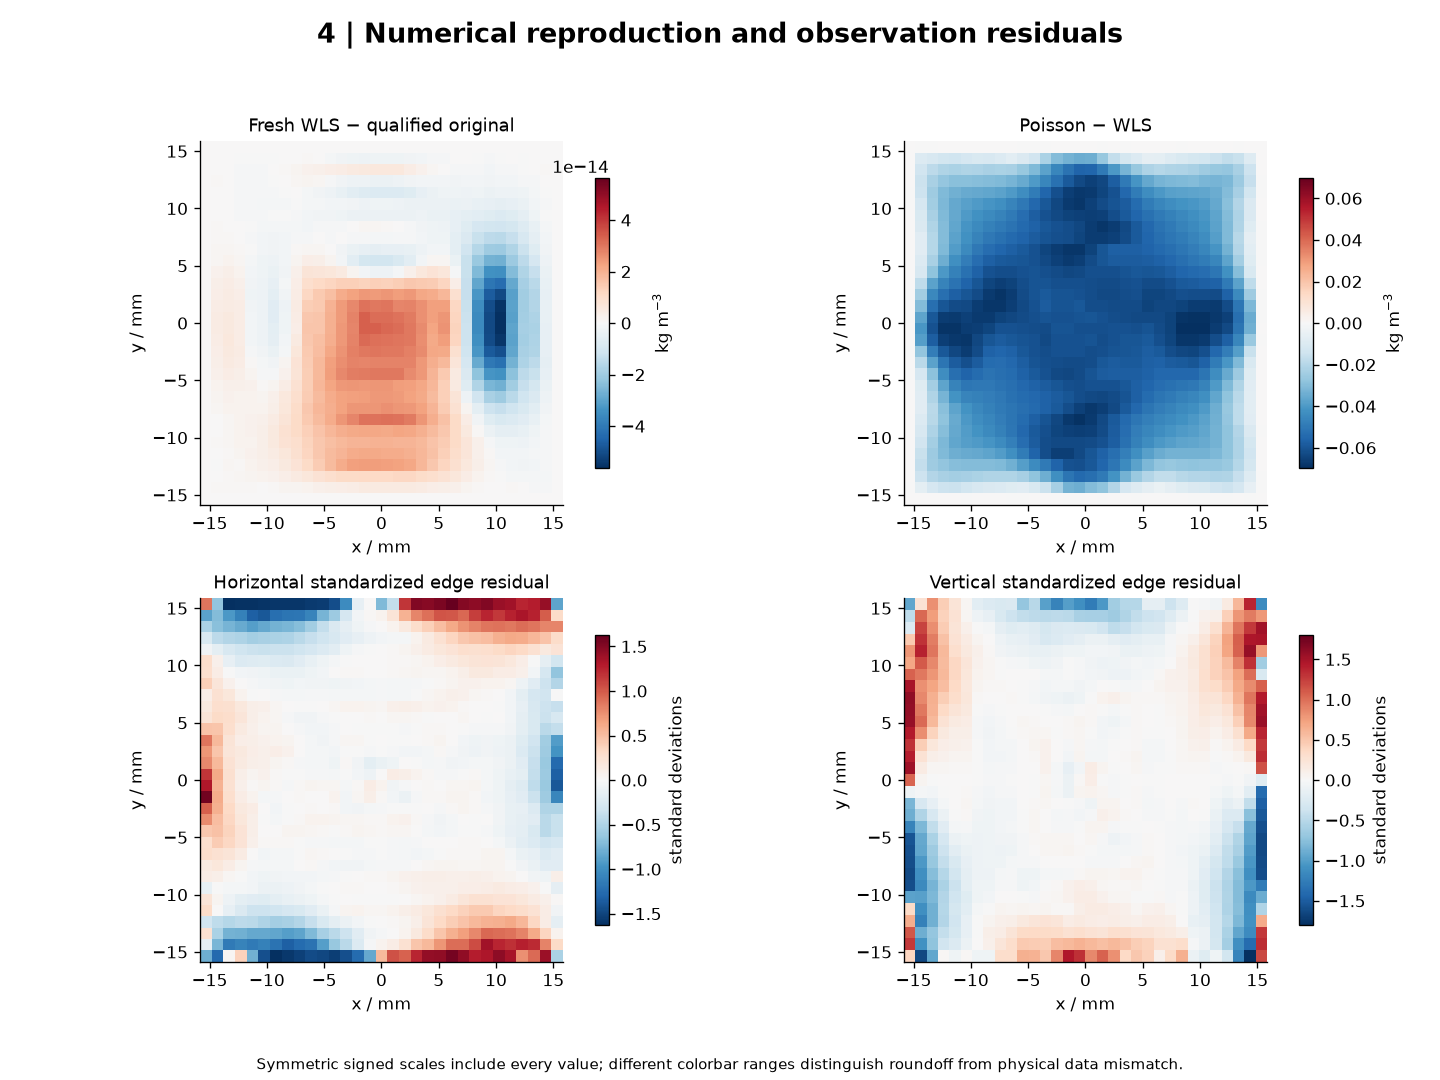

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=wls['reconstruction'],density_sigma=wls['density_sigma'])
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(report,indent=2))
fig=viz.comparisons(wls,poisson,upstream,extent,cal);viz.save_group(fig,FIGDIR,'figure04_residuals');show_inline(fig);plt.close(fig)

## 5. Uncertainty: analytical propagation versus actual independent draws

Draw2048 independent nodal gradient and boundary errors under the fixed conditional model, then solve the same WLS system for each density perturbation. Their empirical standard deviation tests the covariance algebra. This does not establish physical uncertainty coverage or independent true density. The cumulative distributions also retain the original unit-defective output, explicitly labeled; its much smaller sigma is not an improvement.

The normal matrix has a large condition number caused by the extreme boundary precision. The source warning is retained. A separately archived diagonal-equilibration check lowers the condition number from3.10×10¹⁹ to6523 and agrees with the original propagated sigma to6.85×10⁻¹⁵ range-NRMSE; this supports numerical consistency without erasing the source conditioning limitation.

Empirical versus analytic sigma relative-L2 difference: 0.015611746853669024


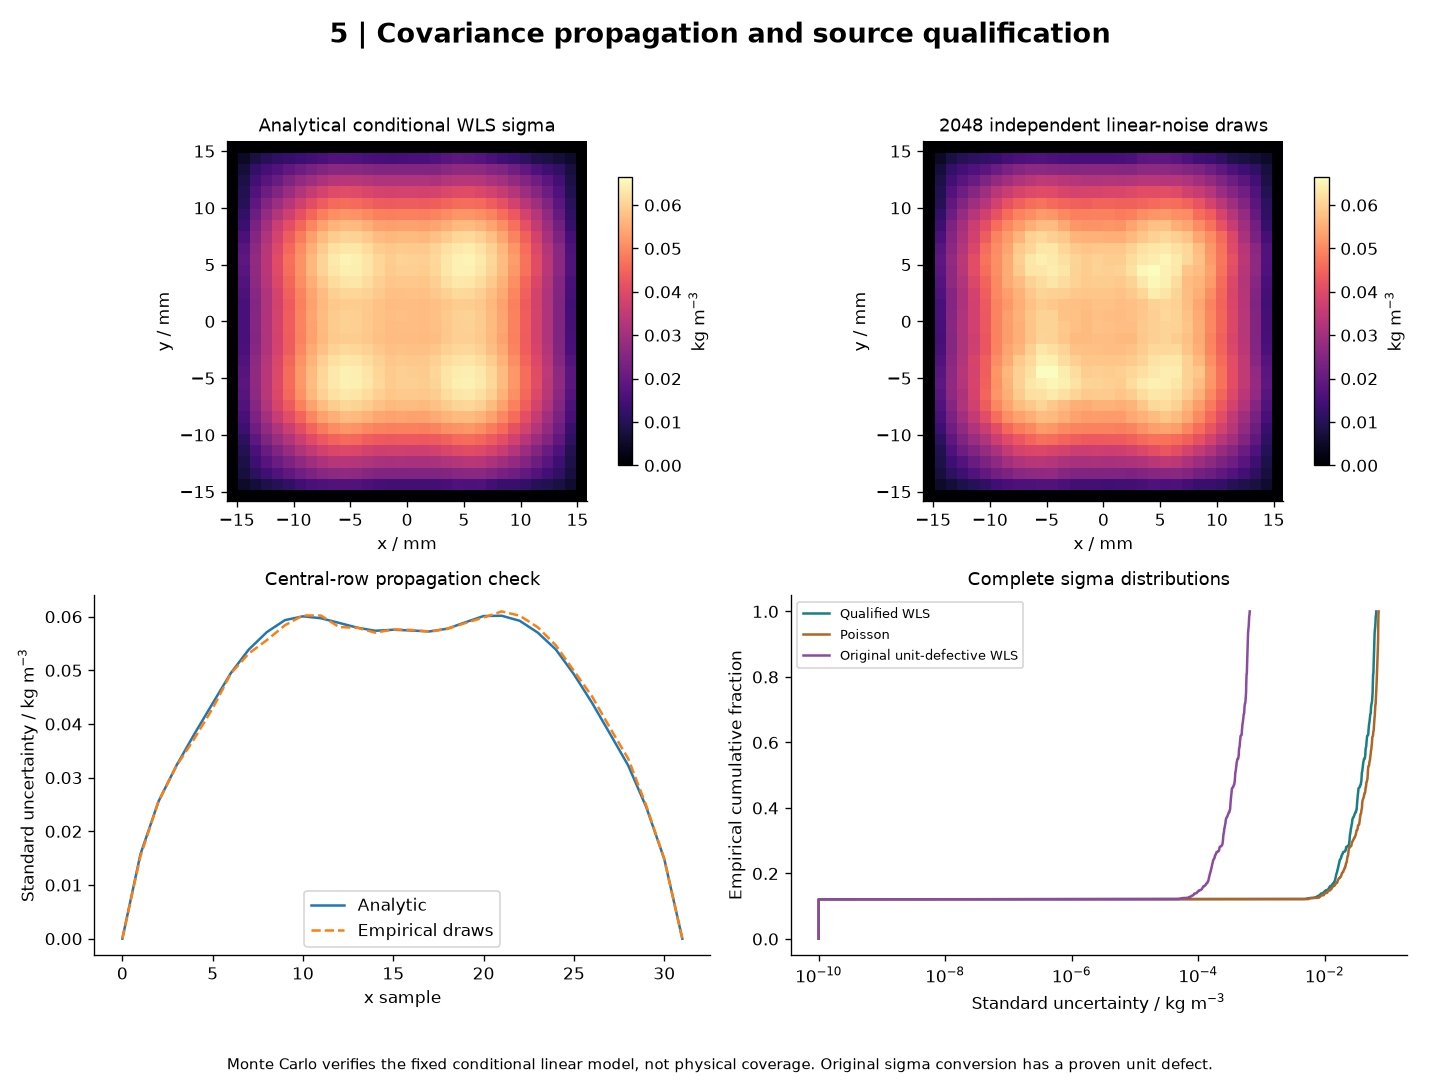

In [5]:
samples=conditional_density_samples(wls['diagnostics'],np.r_[sgx.ravel(),sgy.ravel()],n_draw=2048,seed=731)
empirical_sigma=samples.std(axis=1,ddof=1).reshape(32,32)
sigma_relative_rms=float(np.linalg.norm(empirical_sigma-wls['density_sigma'][0])/np.linalg.norm(wls['density_sigma'][0]))
print('Empirical versus analytic sigma relative-L2 difference:',sigma_relative_rms)
assert sigma_relative_rms<.08
fig=viz.uncertainty(wls,poisson,empirical_sigma,uncorrected,extent);viz.save_group(fig,FIGDIR,'figure05_uncertainty');show_inline(fig);plt.close(fig)
del samples

## 6. Ablations, sensitivity and conclusion

Two fresh ablations isolate uniform gradient weights and displacement-only MC variance; each retains all observations and the known perimeter. Fresh independently seeded sensor-noise perturbations test sensitivity without replacing the bound observations. The paper's true-error weighted comparison cannot be computed for this sample because independent true displacement is unavailable; no proxy is relabeled as true error. Poisson, WLS and their uncertainty comparison remain active.

### Conclusion

The selected inverse recovers a complete conditional density field and its standard uncertainty. Successful source reproduction and observation consistency do not prove physical truth. The slab approximation, source sample calibration, spatial-independence assumption and first-order calibration propagation constrain interpretation.

D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.130240896428564e-19.
  inv=linalg.inv(normal.toarray())


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.2587344082142297e-17.
  inv=linalg.inv(normal.toarray())


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.222663640887474e-20.
  inv=linalg.inv(normal.toarray())


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.2147895487736247e-20.
  inv=linalg.inv(normal.toarray())


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.253936938361603e-20.
  inv=linalg.inv(normal.toarray())


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch8_20261022\staging\tasks\bos_optical_density_field\src\solvers.py:22: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.23817384758623e-20.
  inv=linalg.inv(normal.toarray())


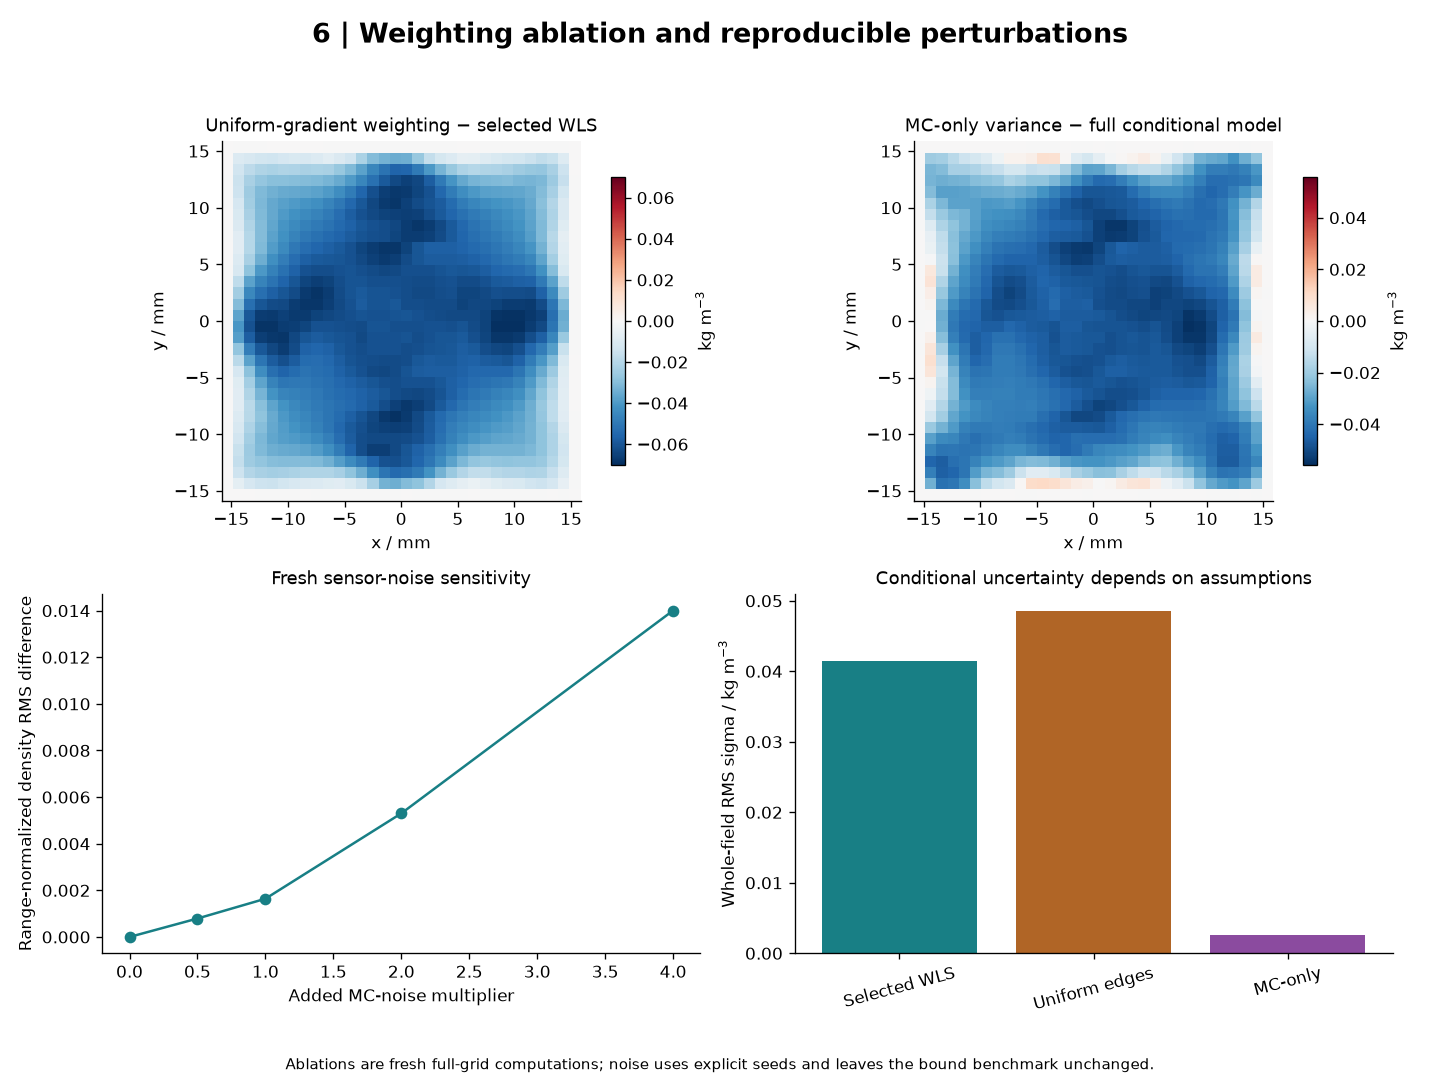

{
  "environment": {
    "sys_executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
    "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
    "numpy": "2.4.6",
    "scipy": "1.17.1",
    "matplotlib": "3.11.1",
    "backend": "Agg",
    "raw_sha256": "a49b86be1b9adfa2da85f0047ae9260bbaf97a11a7cbbb203a1c5404254a6e0c"
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_ncc": 0.9999999999999999,
      "reconstruction_nrmse": 6.738994485430225e-15,
      "density_sigma_ncc": 1.0,
      "density_sigma_nrmse": 4.567946366705146e-15,
      "forward_rms": 0.46454223101939995
    },
    "thresholds": {
      "reconstruction_ncc": {
        "comparison": ">=",
        "boundary": 0.999999999
      },
      "reconstruction_nrmse": {
        "comparison": "<=",
        "boundary": 3.539330494974542e-08
      },
      "density_sigma_ncc": {
        "comparison": ">=",
    

In [6]:
uniform=reconstruct(obs,uniform_weights=True)
c=REFRACTIVE_AMBIENT*PIXEL_PITCH/(MAGNIFICATION*DISTANCE*DEPTH*GLADSTONE_DALE)
mc_only=integrate_wls(x,y,gx,gy,c*sigma[...,0],c*sigma[...,1])
noise_levels=[0.,.5,1.,2.,4.]
noise_results=[reconstruct(add_displacement_noise(obs,level,seed=1200+i)) for i,level in enumerate(noise_levels)]
fig=viz.sensitivity(wls,uniform,mc_only,noise_results,noise_levels,extent);viz.save_group(fig,FIGDIR,'figure06_sensitivity');show_inline(fig);plt.close(fig)
sources=dict(positions=pos,displacement=disp,displacement_sigma=sigma,x=x,y=y,gx=gx,gy=gy,sgx=sgx,sgy=sgy,qualified_upstream_density=upstream['reconstruction'],qualified_upstream_sigma=upstream['density_sigma'],uncorrected_upstream_density=uncorrected['reconstruction'],uncorrected_upstream_sigma=uncorrected['density_sigma'],fresh_wls_density=wls['reconstruction'],fresh_wls_sigma=wls['density_sigma'],fresh_poisson_density=poisson['reconstruction'],fresh_poisson_sigma=poisson['density_sigma'],empirical_sigma=empirical_sigma,uniform_density=uniform['reconstruction'],uniform_sigma=uniform['density_sigma'],mc_only_density=mc_only[0],mc_only_sigma=mc_only[1],noise_levels=np.array(noise_levels),noise_density=np.stack([r['reconstruction'][0] for r in noise_results]),standardized_residual=(wls['diagnostics']['D']@wls['reconstruction'][0].ravel()-wls['diagnostics']['rhs'])*np.sqrt(wls['diagnostics']['weights']))
np.savez_compressed(FIGDIR/'plot_sources.npz',**sources)
measurements=dict(environment=environment,judge=report,wls_runtime_seconds=wls_seconds,poisson_runtime_seconds=poisson_seconds,empirical_sigma_relative_L2=sigma_relative_rms,notebook_runtime_seconds=time.perf_counter()-START,noise_seeds=list(range(1200,1205)),conditional_draw_seed=731,conditional_draw_count=2048)
(FIGDIR/'plot_metrics.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(measurements,indent=2))